Saving traffic_accidents_raw.csv to traffic_accidents_raw (7).csv
Dataset Loaded Successsfully
Dataset shape before cleaning: 3024 rows x 12 columns


========== FIRST 5 RECORDS ==========
  Accident_ID Month_Year   Time                    Location Accident_Severity  \
0     ACC0001     May-21  01:46  Anantnag Jammu and Kashmir           Serious   
1     ACC0002     Jan-18  21:30       Lucknow Uttar Pradesh             Minor   
2     ACC0003     May-23  05:37         Bhilai Chhattisgarh             Minor   
3     ACC0004     Jun-20  00:31       Lucknow Uttar Pradesh             Minor   
4     ACC0005     Aug-21  11:21            Gyalshing Sikkim             Minor   

  Vehicle_Type Weather_Condition         Road_Type  Number_of_Casualties  \
0        Cycle              Hazy  National Highway                   0.0   
1        Truck              Hazy        Urban Road                   5.0   
2   Pedestrian             Foggy  National Highway                   6.0   
3          Bus      

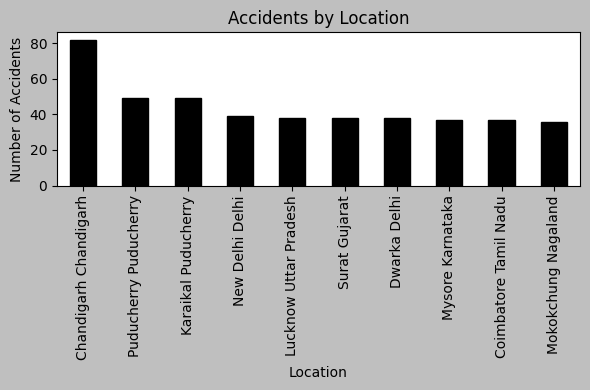

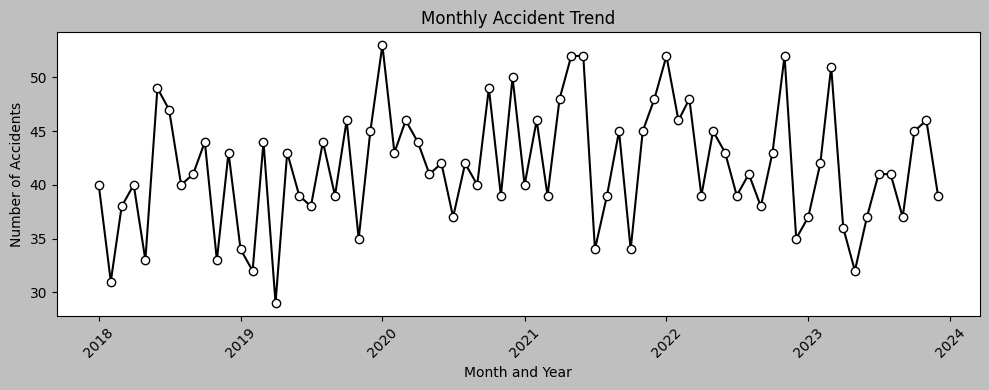

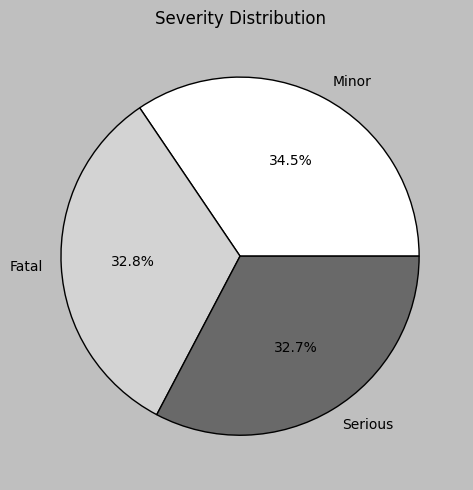



ACCIDENT HOTSPOT ANALYSIS
Top 5 Accident Locations:
Location
Chandigarh Chandigarh    82
Puducherry Puducherry    49
Karaikal Puducherry      49
New Delhi Delhi          39
Lucknow Uttar Pradesh    38
Name: count, dtype: int64

HIGH-RISK MONTH ANALYSIS
Month with highest accidents: Jan-20
Number of accidents: 53

PROJECT SUMMARY
Total accident records: 3000
Total locations: 110

Accident Severity Details:
Accident_Severity
Minor      1034
Fatal       985
Serious     981
Name: count, dtype: int64

Missing values after cleaning: 0

Duplicate records after cleaning: 0

Project Completed Successfully.


In [11]:
# ============================================================
# TRAFFIC ACCIDENT DATA ANALYSIS SYSTEM
# Data Analysis Essentials - Cornerstone Project
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES AND LOAD DATASET
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
uploaded = files.upload()

df = pd.read_csv("traffic_accidents_raw.csv")
df.columns = df.columns.str.strip()
print("Dataset Loaded Successsfully")
print("Dataset shape before cleaning:",
      df.shape[0], "rows x", df.shape[1], "columns")
print("\n")


# ============================================================
# 2. INITIAL DATA INSPECTION
# ============================================================

# First five records
print("========== FIRST 5 RECORDS ==========")
print(df.head())
print("\n")


# Data types
print("========== DATA TYPES ==========")
print(df.dtypes)
print("\n")


# ============================================================
# 3. CATEGORICAL DATA INSPECTION
# ============================================================

categorical_columns = [
    "Accident_Severity",
    "Vehicle_Type",
    "Weather_Condition",
    "Road_Type",
    "Light_Condition"
]

for col in categorical_columns:
    print("==========", col, "CATEGORIES ==========")
    print(df[col].unique())
    print()

# ============================================================
# 4. CHECK DUPLICATE AND MISSING VALUES
# ============================================================

# Duplicate records
print("========== DUPLICATE RECORDS ==========")
print("Duplicate rows detected:", df.duplicated().sum())
print("\n")

# Missing values
print("========== MISSING VALUES ==========")
print("Missing values in each column:\n",df.isnull().sum())
print("Missing values before cleaning: ",
      df.isnull().sum().sum())
print("\n")


# ============================================================
# 5. DATA CLEANING
# ============================================================

# Remove duplicate records
df = df.drop_duplicates()

# Fill missing categorical values using Mode
for col in ["Light_Condition", "Weather_Condition"]:
    df[col] = df[col].fillna(df[col].mode()[0])

# Fill missing numerical values using Median
for col in ["Number_of_Casualties", "Number_of_Fatalities"]:
    df[col] = df[col].fillna(df[col].median())


# ============================================================
# 6. DATA CLEANING RESULTS
# ============================================================

print("========== AFTER CLEANING ==========")

print("Rows              :", df.shape[0])
print("Columns           :", df.shape[1])
print("Missing values    :", df.isnull().sum().sum())
print("Duplicate rows    :", df.duplicated().sum())
print("\n")

print("First 5 records after cleaning:")
print(df.head())
print("\n")


# Save a copy of the cleaned dataset before preprocessing
cleaned_df = df.copy()


# ============================================================
# 7.  STATISTICAL ANALYSIS USING NUMPY
# ============================================================

fatalities = df["Number_of_Fatalities"].values
casualties = df["Number_of_Casualties"].values

print("Statistical Analysis using NumPy")

print("\nFatalities Analysis")
print("Mean:", np.mean(fatalities))
print("Median:", np.median(fatalities))
print("Maximum:", np.max(fatalities))
print("Minimum:", np.min(fatalities))
print("Standard Deviation:", np.std(fatalities))
print()
print("\nCasualties Analysis")
print("Mean:", np.mean(casualties))
print("Median:", np.median(casualties))
print("Maximum:", np.max(casualties))
print("Minimum:", np.min(casualties))
print("Standard Deviation:", np.std(casualties))

# ============================================================
# 8. PANDAS ANALYSIS
# ============================================================
print(df.describe())
print(df["Accident_Severity"].value_counts(),"\n")
print(df["Weather_Condition"].value_counts(),"\n")
print(df["Road_Type"].value_counts(),"\n")

# ============================================================
# 9. DATA PREPROCESSING
# ============================================================

from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder


# ============================================================
# 9.1 FEATURE SCALING
# ============================================================

scaler = MinMaxScaler()

df["Speed_Limit (km/h)"] = scaler.fit_transform(
    df[["Speed_Limit (km/h)"]]
)


# ============================================================
# 9.2 FEATURE STANDARDIZATION
# ============================================================

standard = StandardScaler()

df["Number_of_Casualties"] = standard.fit_transform(
    df[["Number_of_Casualties"]]
)

df["Number_of_Fatalities"] = standard.fit_transform(
    df[["Number_of_Fatalities"]]
)


# ============================================================
# 9.3 LABEL ENCODING
# ============================================================

encoder = LabelEncoder()

df["Accident_Severity"] = encoder.fit_transform(
    df["Accident_Severity"]
)


# Label Mapping
print("========== ACCIDENT SEVERITY LABEL MAPPING ==========")

for i, label in enumerate(encoder.classes_):
    print(label, "=", i)

print("\n")


# ============================================================
# 9.4 ONE-HOT ENCODING
# ============================================================

df = pd.get_dummies(
    df,
    columns=["Vehicle_Type"]
)



# ============================================================
# 10. DATA VISUALIZATION
# ============================================================

plt.style.use("grayscale")


# ---------------------------------------
# Step 10.1 : Accidents by Location
# ---------------------------------------

location = cleaned_df["Location"].value_counts()

plt.figure(figsize=(6, 4))

location.head(10).plot(
    kind="bar",
    color="black",
    edgecolor="black"
)

plt.title("Accidents by Location")
plt.xlabel("Location")
plt.ylabel("Number of Accidents")

plt.tight_layout()
plt.show()
print()

# ---------------------------------------
# Step 10.2 : Monthly Accident Trend
# ---------------------------------------

monthly = cleaned_df["Month_Year"].value_counts()

# Sort months in chronological order
monthly.index = pd.to_datetime(
    monthly.index,
    format="%b-%y"
)

monthly = monthly.sort_index()

plt.figure(figsize=(10, 4))

plt.plot(
    monthly.index,
    monthly.values,
    color="black",
    linestyle="-",
    marker="o",
    markerfacecolor="white",
    markeredgecolor="black"
)

plt.title("Monthly Accident Trend")
plt.xlabel("Month and Year")
plt.ylabel("Number of Accidents")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print()


# ---------------------------------------
# Step 10.3 : Severity Distribution Pie Chart
# ---------------------------------------

severity = cleaned_df["Accident_Severity"].value_counts()

plt.figure(figsize=(5, 5))

severity.plot(
    kind="pie",
    autopct="%1.1f%%",
    colors=["white", "lightgray", "dimgray"],
    wedgeprops={"edgecolor": "black", "linewidth": 1}
)

plt.title("Severity Distribution")
plt.ylabel("")

plt.tight_layout()
plt.show()
print()

# ============================================================
# 11. ACCIDENT HOTSPOT ANALYSIS
# ============================================================

print("\n==============================")
print("ACCIDENT HOTSPOT ANALYSIS")
print("==============================")

hotspots = cleaned_df["Location"].value_counts()

print("Top 5 Accident Locations:")
print(hotspots.head(5))


# ============================================================
# 12. HIGH-RISK MONTH ANALYSIS
# ============================================================

print("\n==============================")
print("HIGH-RISK MONTH ANALYSIS")
print("==============================")

monthly_accidents = cleaned_df["Month_Year"].value_counts()

if len(monthly_accidents) > 0:
    high_month = monthly_accidents.idxmax()
    high_count = monthly_accidents.max()

    print("Month with highest accidents:", high_month)
    print("Number of accidents:", high_count)


# ============================================================
# 13. FINAL PROJECT SUMMARY
# ============================================================

print("\n==============================")
print("PROJECT SUMMARY")
print("==============================")

print("Total accident records:", len(cleaned_df))
print("Total locations:", cleaned_df["Location"].nunique())

print("\nAccident Severity Details:")
print(cleaned_df["Accident_Severity"].value_counts())

print("\nProject Completed Successfully.")